one tree (leaf 20)        : CV ROC AUC 0.748 +/- 0.038   fit 0.01 s
forest (default)          : CV ROC AUC 0.820 +/- 0.034   fit 1.05 s
forest (balanced)         : CV ROC AUC 0.817 +/- 0.034   fit 0.80 s
forest (balanced, leaf 20): CV ROC AUC 0.854 +/- 0.032   fit 0.80 s


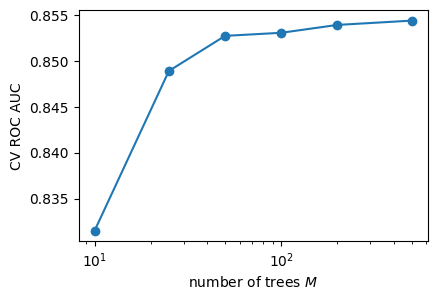

CV ROC AUC (trees): [0.831 0.849 0.853 0.853 0.854 0.854]


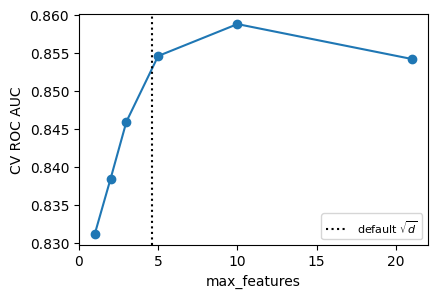

CV ROC AUC (max_features): [0.831 0.838 0.846 0.855 0.859 0.854]


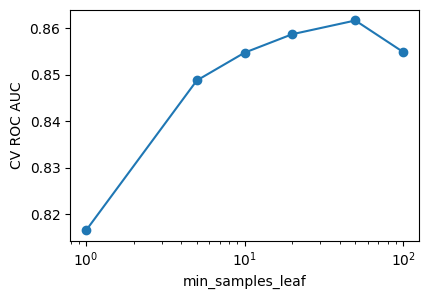

CV ROC AUC (leaf size): [0.817 0.849 0.855 0.859 0.862 0.855]
test ROC AUC 0.826


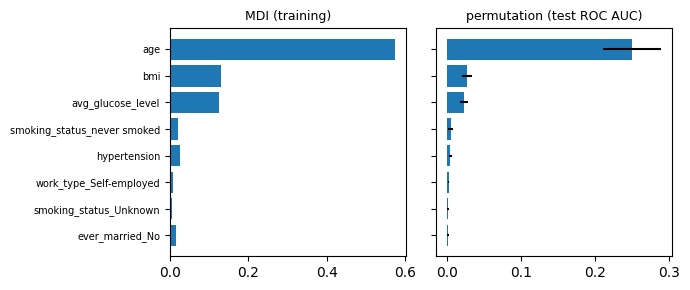

In [ ]:

# 1. Imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

# hello

# 2. Data

df = pd.read_csv("stroke-prediction.csv").drop(columns="id")
X = pd.get_dummies(df.drop(columns="stroke"))          # text columns -> 0/1 columns; missing BMIs kept (forests accept them)
y = df["stroke"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
cv = StratifiedKFold(5, shuffle=True, random_state=0)  # how to split: 5 stratified folds


# 3. One tree vs forests, same folds

for name, m in [("one tree (leaf 20)        ", DecisionTreeClassifier(min_samples_leaf=20, random_state=0)),
                ("forest (default)          ", RandomForestClassifier(200, random_state=0, n_jobs=-1)),
                ("forest (balanced)         ", RandomForestClassifier(200, class_weight="balanced", random_state=0, n_jobs=-1)),
                ("forest (balanced, leaf 20)", RandomForestClassifier(200, class_weight="balanced", min_samples_leaf=20, random_state=0, n_jobs=-1))]:
    r = cross_validate(m, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{name}: CV ROC AUC {r['test_score'].mean():.3f} +/- {r['test_score'].std():.3f}   fit {r['fit_time'].mean():.2f} s")


# 4. How many trees?

Mv = [10, 25, 50, 100, 200, 500]
auc = [cross_val_score(RandomForestClassifier(M, class_weight="balanced", min_samples_leaf=20, random_state=0, n_jobs=-1),
                       X_train, y_train, cv=cv, scoring="roc_auc").mean() for M in Mv]
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.semilogx(Mv, auc, "o-")
ax.set_xlabel("number of trees $M$")
ax.set_ylabel("CV ROC AUC")
plt.show()
print("CV ROC AUC (trees):", np.round(auc, 3))


# 5. How many features per split?

d = X.shape[1]
mfs = [1, 2, 3, 5, 10, d]
auc = [cross_val_score(RandomForestClassifier(200, max_features=k, class_weight="balanced", min_samples_leaf=20,
                                              random_state=0, n_jobs=-1),
                       X_train, y_train, cv=cv, scoring="roc_auc").mean() for k in mfs]
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.plot(mfs, auc, "o-")
ax.axvline(np.sqrt(d), color="k", linestyle=":", label=r"default $\sqrt{d}$")
ax.set_xlabel("max_features")
ax.set_ylabel("CV ROC AUC")
ax.legend(fontsize=8)
plt.show()
print("CV ROC AUC (max_features):", np.round(auc, 3))


# 6. Leaf size

leaves = [1, 5, 10, 20, 50, 100]
auc = [cross_val_score(RandomForestClassifier(200, max_features=10, min_samples_leaf=L, class_weight="balanced",
                                              random_state=0, n_jobs=-1),
                       X_train, y_train, cv=cv, scoring="roc_auc").mean() for L in leaves]
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.semilogx(leaves, auc, "o-")
ax.set_xlabel("min_samples_leaf")
ax.set_ylabel("CV ROC AUC")
plt.show()
print("CV ROC AUC (leaf size):", np.round(auc, 3))


# 7. Final forest, test set once

rf = RandomForestClassifier(200, max_features=10, min_samples_leaf=20, class_weight="balanced",
                            random_state=0, n_jobs=-1).fit(X_train, y_train)
print(f"test ROC AUC {roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]):.3f}")


# 8. Importances

pi = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=0, scoring="roc_auc")
names = X.columns.to_numpy()
top = np.argsort(pi.importances_mean)[::-1][:8]
fig, axs = plt.subplots(1, 2, figsize=(7, 3), sharey=True)
axs[0].barh(range(8)[::-1], rf.feature_importances_[top])
axs[0].set_title("MDI (training)", fontsize=9)
axs[1].barh(range(8)[::-1], pi.importances_mean[top], xerr=pi.importances_std[top])
axs[1].set_title("permutation (test ROC AUC)", fontsize=9)
axs[0].set_yticks(range(8)[::-1], names[top], fontsize=7)
plt.tight_layout()
plt.show()